# 02 · The leakage experiment

Published acoustic detectors for wood-borers report accuracies at or near
100%. Boulila et al. (2023) remark that this dataset seems *"too simple"* for
deep learning. The 2026 systematic review of RPW detection independently
flags **possible leakage** in a reviewed study, and notes that most work uses
inconsistent evaluation protocols and cannot be reproduced on identical data.

This notebook measures the problem.

**The issue.** The data is organised as recording folders, one per deployed
device. Every folder shares a tree, a sensor, a mounting and a background
environment. Split clips at random and clips from one folder land on both
sides of the train/test boundary — so a model can score almost perfectly by
recognising *the recording* rather than *the insect*.

**The test that matters.** Hold out whole trees. Does it work on a tree it has
never heard?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # the nakheel-guard folder
for sub in ("src", "scripts"):
    sys.path.insert(0, str(ROOT / sub))

# These imports are wrapped because the most common way they fail on Anaconda
# produces an error that never mentions the real cause. Installing an audio
# library with pip can upgrade NumPy past 2.0, and Anaconda's pre-compiled
# matplotlib / scipy / pandas were built against NumPy 1.x -- so the failure
# surfaces as "initialization failed" deep inside matplotlib's import chain,
# with no hint that NumPy is responsible.
try:
    import numpy as np, pandas as pd, matplotlib.pyplot as plt
except ImportError as _exc:
    _numpy_version = "unknown"
    try:
        import numpy as _np_probe
        _numpy_version = _np_probe.__version__
    except Exception:
        pass
    raise ImportError(f"""Core imports failed. NumPy version: {_numpy_version}

This is almost always a mixed environment: some packages were built for
NumPy 1.x and others require NumPy 2.x, so no single NumPy version satisfies
everything. Typical symptoms are "module compiled using NumPy 1.x cannot be
run in NumPy 2" or "module 'numpy' has no attribute 'long'".

Pinning NumPy does NOT fix this -- in a genuinely mixed environment each pin
only moves the failure to a different package. Build a clean environment:

    conda create -n nakheel python=3.11 -y
    conda activate nakheel
    pip install -r requirements.txt
    pip install jupyterlab ipykernel
    python -m ipykernel install --user --name nakheel --display-name "Python (nakheel)"

then start Jupyter from that prompt and choose
Kernel -> Change Kernel -> Python (nakheel).

If a package is merely missing rather than mismatched, install it into THIS
kernel with:

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed <package>

Original error: {_exc}
""") from _exc

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

In [2]:
# ---------------------------------------------------------------- packages
# Check the packages this project needs are importable *in the Python that is
# running this notebook*. On Anaconda, `pip` on the command line often points
# at a different environment than Jupyter uses, which is a common and
# confusing source of "but I installed it" failures.
_missing = []
for _mod, _pkg in [("numpy", "numpy"), ("pandas", "pandas"),
                   ("sklearn", "scikit-learn"), ("scipy", "scipy"),
                   ("librosa", "librosa"), ("soundfile", "soundfile"),
                   ("joblib", "joblib"), ("matplotlib", "matplotlib"),
                   ("openpyxl", "openpyxl")]:
    try:
        __import__(_mod)
    except ImportError:
        _missing.append(_pkg)

if _missing:
    raise ImportError(f"""Missing packages: {', '.join(_missing)}

Install them into THIS kernel by running the following in a new cell,
then restart the kernel (Kernel -> Restart):

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed {' '.join(_missing)}

The --upgrade-strategy flag matters: without it pip may upgrade NumPy to
satisfy the new package, which can break other packages compiled against a
different NumPy generation. If that happens, see the README -- the fix is a
clean environment, not a NumPy pin.
""")

print("packages: OK")

# ---------------------------------------------------------------- dataset
# "mock"      - structurally faithful stand-in, synthetic audio. For testing.
# "treevibes" - the real download. Put it in data/treevibes/.
WHICH = "treevibes"

DATASETS = {
    "mock":      ROOT / "data" / "mock_treevibes",
    "treevibes": ROOT / "data" / "treevibes",
}
DATASET = DATASETS[WHICH]
TAG = "mock" if WHICH == "mock" else "treevibes"

# The Kaggle distribution splits into field/ and lab/. Only the field
# recordings describe deployed sensors on real trees -- the lab set is
# controlled-condition material that would both swamp the field data (roughly
# 53,000 clips against 4,000) and mix two very different acoustic regimes
# under one label. The published analyses use the field recordings, so that
# is what this project evaluates on.
if WHICH == "treevibes" and (DATASET / "field").is_dir():
    DATASET = DATASET / "field"
    print("using the field recordings only (lab/ excluded)")

if not DATASET.exists():
    if WHICH == "mock":
        # Imported and called directly rather than run as a subprocess, so a
        # failure arrives as an ordinary traceback naming its cause instead
        # of an opaque "non-zero exit status 1".
        import make_mock_treevibes
        print("building the mock dataset (a few minutes)...")
        make_mock_treevibes.generate(out=DATASET, folders=10, days=110,
                                     per_day=2, seconds=3.0)
    else:
        raise FileNotFoundError(f"""{DATASET} not found.

Download TreeVibes from
    https://www.kaggle.com/datasets/potamitis/treevibes
and extract it into
    {DATASET}
""")
print(f"dataset: {DATASET}  (tag '{TAG}')")

packages: OK
using the field recordings only (lab/ excluded)
dataset: C:\Users\DELL\Downloads\nakheel-final\nakheel-final\data\treevibes\field  (tag 'treevibes')


In [3]:
import extract as E, data as D

cached = E.load_cache(TAG)
if cached is None:
    raise FileNotFoundError(f"No cached features for '{TAG}'. Run notebook 01.")
X, y, groups, clip_ids, names = cached
print(f"{X.shape[0]} windows x {X.shape[1]} features, {len(set(groups))} trees")

38675 windows x 261 features, 36 trees


## 1. The same model, two protocols

Nothing changes except how the folds are drawn.

In [4]:
import train as T

grouped = T.cross_validate(X, y, groups, "grouped", n_splits=5)
random_ = T.cross_validate(X, y, groups, "random",  n_splits=5)

T.print_table("GROUPED  (test trees unseen) — the honest number", grouped)
T.print_table("RANDOM   (clips shuffled) — literature protocol", random_)


GROUPED  (test trees unseen) — the honest number
------------------------------------------------------------------------------
model                   balanced_     recall  specifici  precision         f1    roc_auc     pr_auc
logistic_regression     0.485±0.08  0.588±0.04  0.382±0.15  0.573±0.06  0.579±0.04  0.462±0.12  0.574±0.10
random_forest           0.482±0.03  0.923±0.11  0.041±0.05  0.569±0.03  0.701±0.05  0.546±0.11  0.622±0.09

RANDOM   (clips shuffled) — literature protocol
------------------------------------------------------------------------------
model                   balanced_     recall  specifici  precision         f1    roc_auc     pr_auc
logistic_regression     0.890±0.00  0.883±0.00  0.896±0.01  0.922±0.00  0.902±0.00  0.954±0.00  0.964±0.00
random_forest           0.854±0.00  1.000±0.00  0.709±0.01  0.827±0.00  0.905±0.00  0.995±0.00  0.996±0.00


In [5]:
best = max(grouped, key=lambda n: grouped[n]["mean"]["balanced_accuracy"])
g = grouped[best]["mean"]["balanced_accuracy"]
r = random_[best]["mean"]["balanced_accuracy"]
print(f"best model: {best}")
print(f"  grouped {g:.3f}   random {r:.3f}   gap {r - g:+.3f}")

best model: logistic_regression
  grouped 0.485   random 0.890   gap +0.405


## 2. Why it happens: tree identity is learnable

If a model can tell *which tree* a recording came from, it has a shortcut to
the label whenever a tree is wholly clean or wholly infested. Test that
directly.

In [6]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

gid = LabelEncoder().fit_transform(groups)
acc = cross_val_score(
    RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=0),
    X, gid, cv=3, scoring="accuracy").mean()
print(f"tree identity predicted with accuracy {acc:.3f} "
      f"(chance {1/len(set(groups)):.3f})")
print("The higher this is, the more a random split leaks.")

tree identity predicted with accuracy 0.868 (chance 0.028)
The higher this is, the more a random split leaks.


## 3. Save and plot

In [7]:
import json, joblib
from config import RESULTS_DIR, MODEL_PATH, FALSE_ALARM_BUDGET

final = T.make_models()[best]
final.fit(X, y)
thr = T.threshold_for_false_alarm_budget(y, T._scores_of(final, X))
joblib.dump({"model": final, "threshold": thr, "feature_names": names,
             "model_name": best}, MODEL_PATH)

report = {
    "dataset": WHICH, "best_model": best, "decision_threshold": float(thr),
    "false_alarm_budget": FALSE_ALARM_BUDGET,
    "n_windows": int(X.shape[0]), "n_features": int(X.shape[1]),
    "n_groups": int(len(set(groups))),
    "tree_identity_accuracy": float(acc),
    "grouped": grouped, "random": random_,
    "leakage_gap_balanced_accuracy": float(r - g),
}
(RESULTS_DIR / "report.json").write_text(json.dumps(report, indent=2, default=float))
print("saved results/report.json and results/model.joblib")

saved results/report.json and results/model.joblib


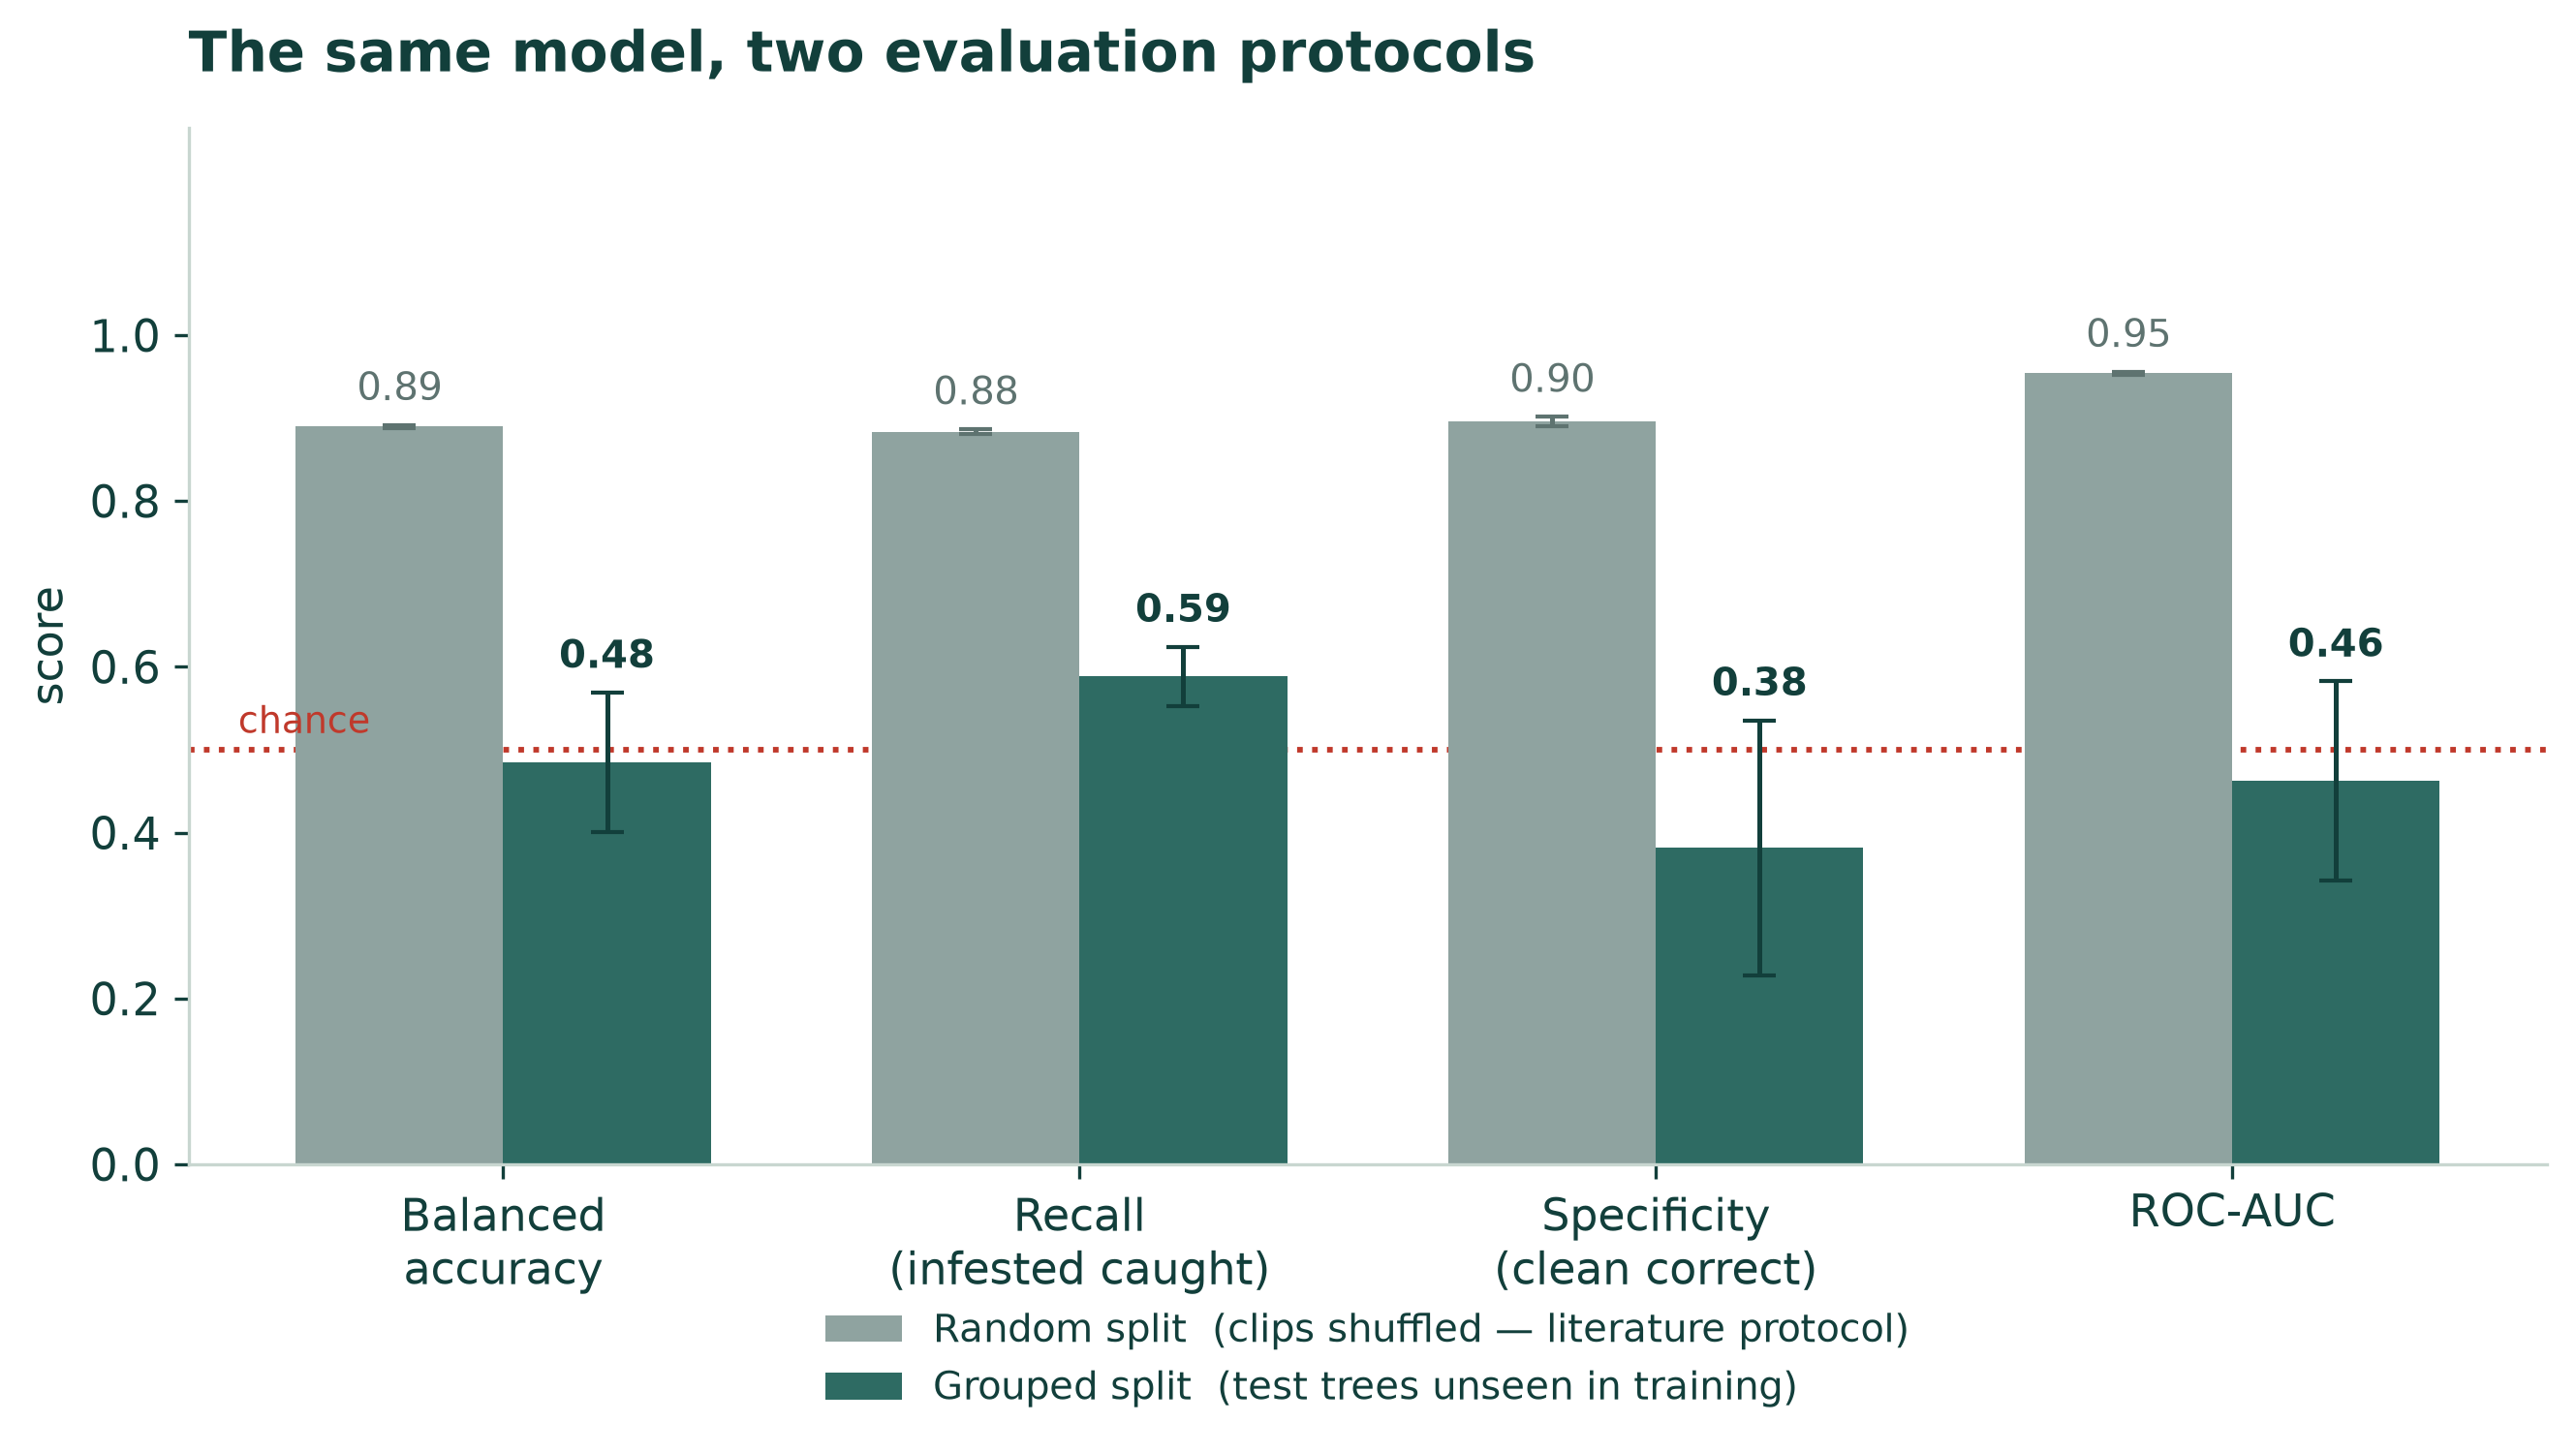

In [8]:
import plots as P
from IPython.display import Image, display
P.fig_leakage(report); P.fig_confusion(report)
display(Image(str(P.RESULTS_DIR / "fig_leakage.png"), width=780))

### What to take from this

A large gap means **cross-tree generalisation is the real bottleneck**, and
that published single-number accuracies on this data do not describe field
performance.

Notebook 03 addresses that — not by fighting tree-to-tree variation, but by
removing the need to generalise across trees at all.

In [9]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

gid = LabelEncoder().fit_transform(groups)
acc = cross_val_score(
    RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=0),
    X, gid, cv=3, scoring="accuracy").mean()
print(f"tree identity predicted with accuracy {acc:.3f} (chance {1/len(set(groups)):.3f})")

tree identity predicted with accuracy 0.868 (chance 0.028)
